========== ENTER FACTS ==========
Enter facts one by one.
Press Enter on an empty line to stop.
Fact: American(Robert)
Fact: Missile(T1)
Fact: Owns(A, T1)
Fact: Enemy(A, America)
Fact: 

========== ENTER RULES ==========
Enter rules one by one.
Press Enter on an empty line to stop.
Rule: Enemy(x, America) => Hostile(x)
Rule: Missile(x) => Weapon(x)
Rule: Missile(x) ^ Owns(A, x) => Sells(Robert, x, A)
Rule: American(p) ^ Weapon(q) ^ Sells(p, q, r) ^ Hostile(r) => Criminal(p)
Rule: 

========== FORWARD CHAINING ==========

Rule Applied:
Enemy(A, America)
------------------------------
Derived: Hostile(A)

Rule Applied:
Missile(T1)
------------------------------
Derived: Weapon(T1)

Rule Applied:
Missile(T1)
Owns(A, T1)
------------------------------
Derived: Sells(Robert, T1, A)

Rule Applied:
American(Robert)
Weapon(T1)
Sells(Robert, T1, A)
Hostile(A)
------------------------------
Derived: Criminal(Robert)

========== FINAL FACTS ==========
American(Robert)
Criminal(Robert)
Enemy(A, Am

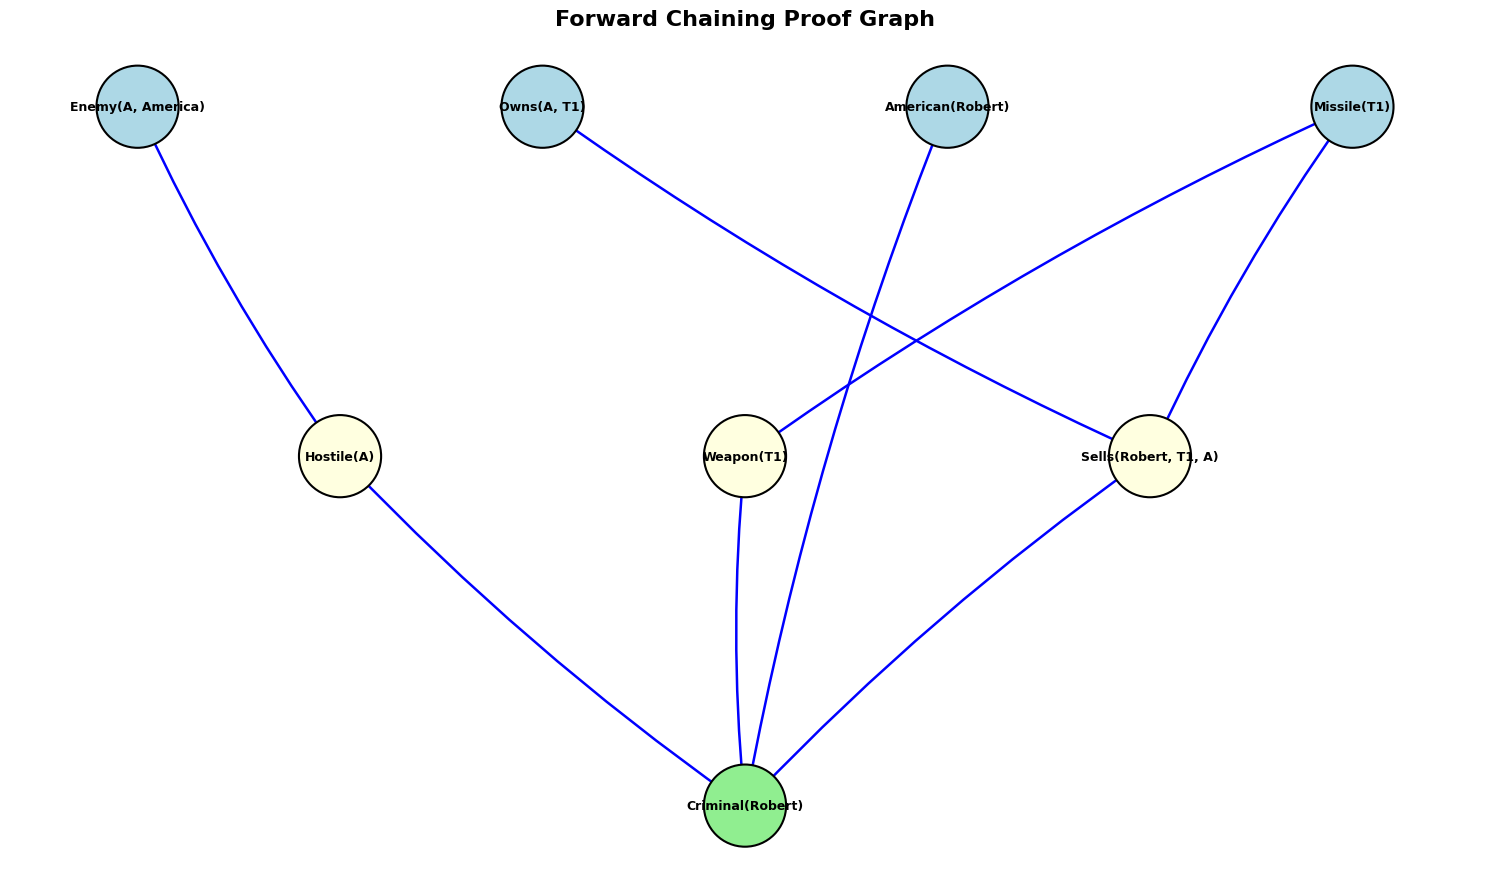

In [2]:

import re
import networkx as nx
import matplotlib.pyplot as plt

# -----------------------------------
# 1. GET FACTS FROM USER
# -----------------------------------

facts = set()

print("========== ENTER FACTS ==========")
print("Enter facts one by one.")
print("Press Enter on an empty line to stop.")

while True:

    fact = input("Fact: ").strip()

    if fact == "":
        break

    facts.add(fact)


# -----------------------------------
# 2. GET RULES FROM USER
# -----------------------------------

rules = []

print("\n========== ENTER RULES ==========")
print("Enter rules one by one.")
print("Press Enter on an empty line to stop.")

while True:

    rule = input("Rule: ").strip()

    if rule == "":
        break

    left, right = rule.split("=>", 1)

    premises = [p.strip() for p in left.split("^")]

    conclusion = right.strip()

    rules.append((premises, conclusion))


# -----------------------------------
# 3. PARSE PREDICATES
# -----------------------------------

def parse(atom):

    match = re.fullmatch(r"\s*(\w+)\((.*?)\)\s*", atom)

    if not match:
        return None, []

    name = match.group(1)

    arguments = [
        x.strip() for x in match.group(2).split(",")
    ]

    return name, arguments


# -----------------------------------
# 4. CHECK VARIABLES
# -----------------------------------

def is_variable(x):

    return x.islower()


# -----------------------------------
# 5. UNIFICATION
# -----------------------------------

def unify(pattern, fact, substitution):

    p_name, p_args = parse(pattern)

    f_name, f_args = parse(fact)

    if p_name != f_name:
        return None

    if len(p_args) != len(f_args):
        return None

    new_sub = substitution.copy()

    for p, f in zip(p_args, f_args):

        if is_variable(p):

            if p in new_sub:

                if new_sub[p] != f:
                    return None

            else:
                new_sub[p] = f

        elif p != f:

            return None

    return new_sub


# -----------------------------------
# 6. FIND MATCHING FACTS
# -----------------------------------

def find_matches(premises, facts):

    results = []

    def search(index, substitution, used_facts):

        if index == len(premises):

            results.append((
                substitution.copy(),
                used_facts.copy()
            ))

            return

        pattern = premises[index]

        for fact in sorted(facts):

            new_sub = unify(
                pattern,
                fact,
                substitution
            )

            if new_sub is not None:

                search(
                    index + 1,
                    new_sub,
                    used_facts + [fact]
                )

    search(0, {}, [])

    return results


# -----------------------------------
# 7. APPLY SUBSTITUTION
# -----------------------------------

def substitute(expression, substitution):

    name, arguments = parse(expression)

    new_arguments = []

    for arg in arguments:

        if arg in substitution:

            new_arguments.append(substitution[arg])

        else:

            new_arguments.append(arg)

    return name + "(" + ", ".join(new_arguments) + ")"


# -----------------------------------
# 8. FORWARD CHAINING
# -----------------------------------

graph = nx.DiGraph()

# Add initial facts
for fact in facts:

    graph.add_node(fact)

initial_facts = facts.copy()

print("\n========== FORWARD CHAINING ==========")

changed = True

while changed:

    changed = False

    for premises, conclusion in rules:

        matches = find_matches(premises, facts)

        for substitution, matched_facts in matches:

            new_fact = substitute(
                conclusion,
                substitution
            )

            if new_fact not in facts:

                facts.add(new_fact)

                changed = True

                graph.add_node(new_fact)

                print("\nRule Applied:")

                for parent in matched_facts:

                    print(parent)

                    graph.add_edge(
                        parent,
                        new_fact
                    )

                print("------------------------------")

                print("Derived:", new_fact)


# -----------------------------------
# 9. DISPLAY FINAL FACTS
# -----------------------------------

print("\n========== FINAL FACTS ==========")

for fact in sorted(facts):

    print(fact)


# -----------------------------------
# 10. GET GOAL FROM USER
# -----------------------------------

print("\n========== ENTER GOAL ==========")

goal = input("Enter the goal to prove: ").strip()

print("\n========== RESULT ==========")

if goal in facts:

    print("PROVED SUCCESSFULLY!")

    print(goal, "is TRUE.")

else:

    print("GOAL NOT PROVED.")

    print(goal, "cannot be derived.")


# -----------------------------------
# 11. DRAW ORGANIZED GRAPH
# -----------------------------------

if goal in graph.nodes():

    plt.figure(figsize=(15, 9))

    # Find the level of every node
    levels = {}

    for node in nx.topological_sort(graph):

        parents = list(graph.predecessors(node))

        if len(parents) == 0:

            levels[node] = 0

        else:

            levels[node] = 1 + max(
                levels[parent] for parent in parents
            )

    # Group nodes according to levels
    level_nodes = {}

    for node, level in levels.items():

        if level not in level_nodes:

            level_nodes[level] = []

        level_nodes[level].append(node)

    # Arrange nodes horizontally and vertically
    positions = {}

    for level, nodes in level_nodes.items():

        count = len(nodes)

        for i, node in enumerate(nodes):

            x = (i - (count - 1) / 2) * 3.5

            y = -level * 2.5

            positions[node] = (x, y)

    # Assign node colors
    colors = []

    for node in graph.nodes():

        if node == goal:

            colors.append("lightgreen")

        elif node in initial_facts:

            colors.append("lightblue")

        else:

            colors.append("lightyellow")

    # Draw nodes
    nx.draw_networkx_nodes(
        graph,
        positions,
        node_size=3500,
        node_color=colors,
        edgecolors="black",
        linewidths=1.5
    )

    # Draw node labels
    nx.draw_networkx_labels(
        graph,
        positions,
        font_size=9,
        font_weight="bold"
    )

    # Draw directional arrows
    nx.draw_networkx_edges(
        graph,
        positions,
        arrows=True,
        arrowsize=25,
        edge_color="blue",
        width=1.8,
        connectionstyle="arc3,rad=0.05"
    )

    plt.title(
        "Forward Chaining Proof Graph",
        fontsize=16,
        fontweight="bold"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()

else:

    print("Graph cannot be generated because goal is not derived.")
